In [9]:

# 1. Importación de librerías

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from pathlib import Path

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


TensorFlow: 2.21.0
NumPy: 2.5.4
Pandas: 3.0.6


## 2. Carga y revisión de los datos preparados

In [10]:
# Localizar la carpeta principal del proyecto
project_root = Path.cwd()

if not (project_root / "data" / "processed" / "X_train.csv").exists():
    project_root = project_root.parent

data_dir = project_root / "data" / "processed"

# Verificar que existan los archivos necesarios
files = [
    "X_train.csv",
    "X_test.csv",
    "y_train_classification.csv",
    "y_test_classification.csv"
]

for file in files:
    if not (data_dir / file).exists():
        raise FileNotFoundError(
            f"No se encontró el archivo: {data_dir / file}"
        )

# Cargar las características de entrenamiento y prueba
X_train = pd.read_csv(data_dir / "X_train.csv")
X_test = pd.read_csv(data_dir / "X_test.csv")

# Cargar las etiquetas de clasificación
y_train_classification = pd.read_csv(
    data_dir / "y_train_classification.csv"
).squeeze("columns")

y_test_classification = pd.read_csv(
    data_dir / "y_test_classification.csv"
).squeeze("columns")

# Mostrar las dimensiones de los conjuntos
print("Dimensiones de los datos:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train_classification.shape)
print("y_test:", y_test_classification.shape)

# Revisar las columnas disponibles
print("\nVariables predictoras:")
print(X_train.columns.tolist())

# Verificar que entrenamiento y prueba tengan las mismas columnas
assert X_train.columns.equals(X_test.columns), (
    "Las columnas de entrenamiento y prueba no coinciden."
)

# Verificar que las etiquetas correspondan a las filas
assert len(X_train) == len(y_train_classification), (
    "La cantidad de filas de entrenamiento no coincide."
)

assert len(X_test) == len(y_test_classification), (
    "La cantidad de filas de prueba no coincide."
)

# Comprobar que la variable objetivo no esté entre las entradas
assert "quality" not in X_train.columns, (
    "La variable quality no debe utilizarse como entrada."
)
assert "high_quality" not in X_train.columns, (
    "La variable high_quality no debe utilizarse como entrada."
)

# Revisar datos faltantes
print("\nDatos faltantes:")
print("X_train:", X_train.isnull().sum().sum())
print("X_test:", X_test.isnull().sum().sum())
print("y_train:", y_train_classification.isnull().sum())
print("y_test:", y_test_classification.isnull().sum())

# Revisar las clases presentes en el objetivo
print("\nDistribución de clases en entrenamiento:")
print(y_train_classification.value_counts().sort_index())

print("\nDistribución de clases en prueba:")
print(y_test_classification.value_counts().sort_index())

print("\nRevisión inicial completada correctamente.")

Dimensiones de los datos:
X_train: (4256, 12)
X_test: (1064, 12)
y_train: (4256,)
y_test: (1064,)

Variables predictoras:
['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol', 'wine_type_white']

Datos faltantes:
X_train: 0
X_test: 0
y_train: 0
y_test: 0

Distribución de clases en entrenamiento:
high_quality
0    3449
1     807
Name: count, dtype: int64

Distribución de clases en prueba:
high_quality
0    862
1    202
Name: count, dtype: int64

Revisión inicial completada correctamente.


## 3. Análisis de correlación con `high_quality`

Correlación de las variables con high_quality:


,Correlación
alcohol,0.422594
density,-0.297680
chlorides,-0.158681
volatile_acidity,-0.142750
residual_sugar,-0.085749
wine_type_white,0.080539
total_sulfur_dioxide,-0.074100
citric_acid,0.058113
fixed_acidity,-0.042601
ph,0.041527


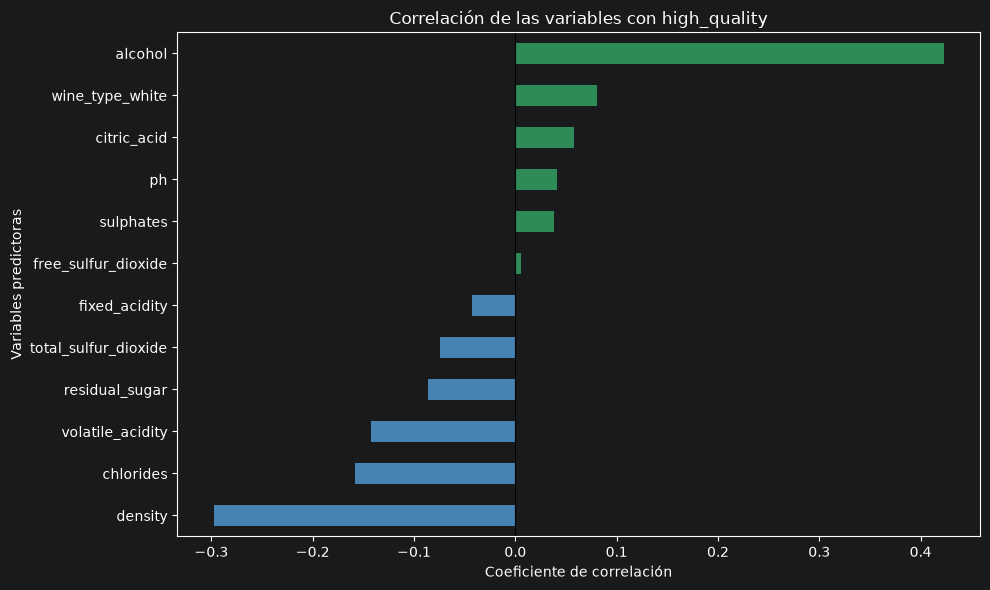

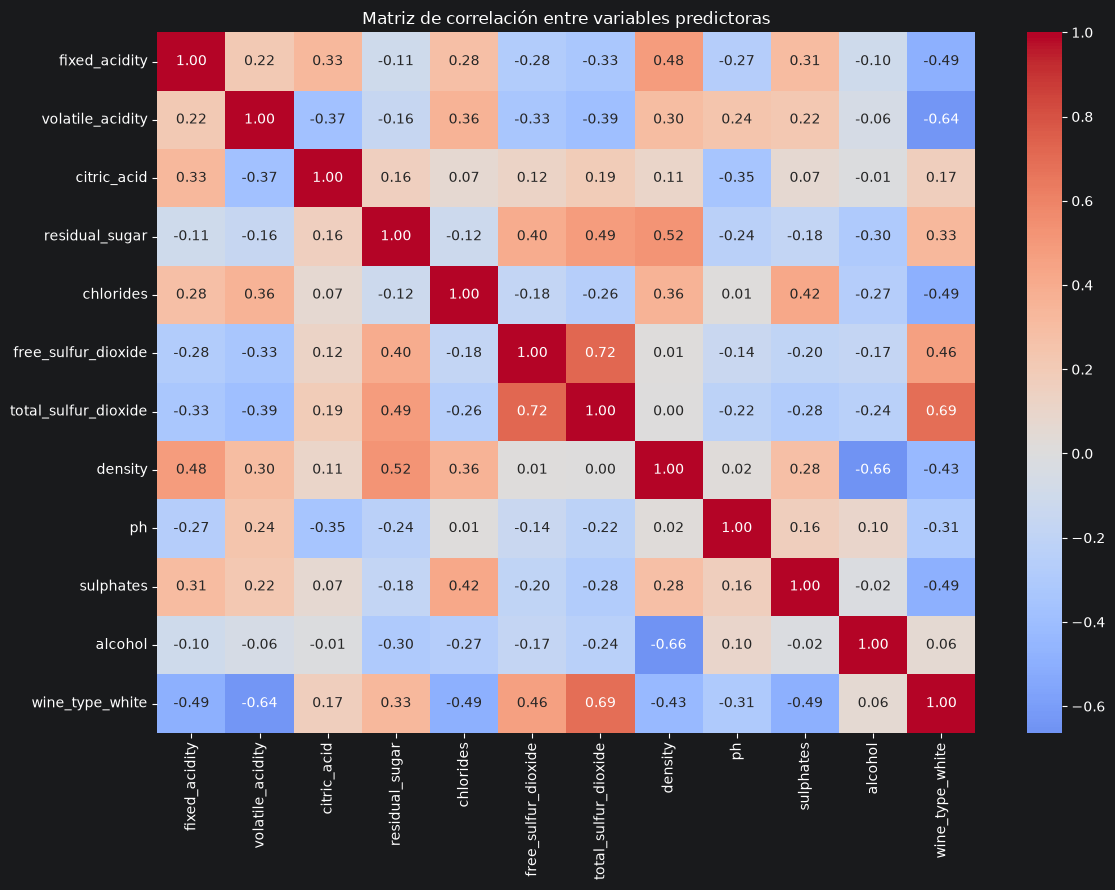

In [11]:
# 3. Análisis de correlación con high_quality

# Crear un DataFrame temporal con las variables predictoras
# y la variable objetivo de clasificación
df_corr = X_train.copy()
df_corr["high_quality"] = y_train_classification.to_numpy()

# Calcular la matriz de correlación
correlation_matrix = df_corr.corr()

# Obtener la correlación de cada variable con high_quality
target_correlation = (
    correlation_matrix["high_quality"]
    .drop("high_quality")
    .sort_values(key=abs, ascending=False)
)

print("Correlación de las variables con high_quality:")
display(target_correlation.to_frame(name="Correlación"))

# Graficar la relación de cada variable con el objetivo
plt.figure(figsize=(10, 6))

target_correlation.sort_values().plot(
    kind="barh",
    color=[
        "steelblue" if value < 0 else "seagreen"
        for value in target_correlation.sort_values()
    ]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlación de las variables con high_quality")
plt.xlabel("Coeficiente de correlación")
plt.ylabel("Variables predictoras")
plt.tight_layout()
plt.show()

# Analizar las correlaciones entre las variables predictoras
feature_correlation = X_train.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    feature_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlación entre variables predictoras")
plt.tight_layout()
plt.show()

## 4. Selección de variables predictoras

In [12]:
# 4. Selección de variables predictoras

# Variables seleccionadas para el segundo modelo
selected_features = [
    "alcohol",
    "density",
    "chlorides",
    "volatile_acidity",
    "wine_type_white",
    "citric_acid"
]

# Verificar que todas las variables existan
missing_features = [
    feature for feature in selected_features
    if feature not in X_train.columns
]

if missing_features:
    raise ValueError(
        f"No se encontraron estas variables: {missing_features}"
    )

# Crear conjuntos reducidos para el segundo modelo
X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

# Mostrar las dimensiones de los nuevos conjuntos
print("Variables seleccionadas:")
print(selected_features)

print("\nDimensiones de los conjuntos reducidos:")
print("X_train_selected:", X_train_selected.shape)
print("X_test_selected:", X_test_selected.shape)

print("\nSelección de variables completada.")

Variables seleccionadas:
['alcohol', 'density', 'chlorides', 'volatile_acidity', 'wine_type_white', 'citric_acid']

Dimensiones de los conjuntos reducidos:
X_train_selected: (4256, 6)
X_test_selected: (1064, 6)

Selección de variables completada.


## 5. Construcción, entrenamiento y evaluación de la ANN con todas las variables (Modelo 1)

### 5.1. Construcción de la arquitectura A (12 y 6 neuronas)

In [13]:
# 5.1. Construcción de la arquitectura A (12 y 6 neuronas)

# Cantidad de variables de entrada
num_neuronas = X_train.shape[1]

# Crear la red neuronal artificial
model_all_12_6 = Sequential()

# Capa de entrada y primera capa oculta
model_all_12_6.add(
    Input(shape=(num_neuronas,))
)
model_all_12_6.add(
    Dense(units=num_neuronas, activation="relu")
)

# Segunda capa oculta
model_all_12_6.add(
    Dense(
        units=int(np.round(num_neuronas / 2)),
        activation="relu"
    )
)

# Capa de salida para clasificación binaria
model_all_12_6.add(
    Dense(units=1, activation="sigmoid")
)

# Compilar el modelo
model_all_12_6.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# Mostrar la arquitectura
model_all_12_6.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │            78 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241 (964.00 B)

 Trainable params: 241 (964.00 B)

 Non-trainable params: 0 (0.00 B)

### 5.2. Entrenamiento inicial y visualización de las curvas de aprendizaje

In [14]:
# 5.2. Entrenamiento inicial de la ANN (12 y 6 neuronas)

history_all_12_6 = model_all_12_6.fit(
    X_train,
    y_train_classification,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7714 - loss: 0.5299 - val_accuracy: 0.8239 - val_loss: 0.4567
Epoch 2/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8140 - loss: 0.4474 - val_accuracy: 0.8333 - val_loss: 0.4158
Epoch 3/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8205 - loss: 0.4171 - val_accuracy: 0.8333 - val_loss: 0.3899
Epoch 4/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8240 - loss: 0.3988 - val_accuracy: 0.8380 - val_loss: 0.3749
Epoch 5/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8255 - loss: 0.3880 - val_accuracy: 0.8415 - val_loss: 0.3649
Epoch 6/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8249 - loss: 0.3819 - val_accuracy: 0.8462 - val_loss: 0.3580
Epoch 7/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8293 - loss: 0.3771 - val_accuracy: 0.8521 - val_loss: 0.3537
Epoch 8/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8323 - loss: 0.3735 - val_accu

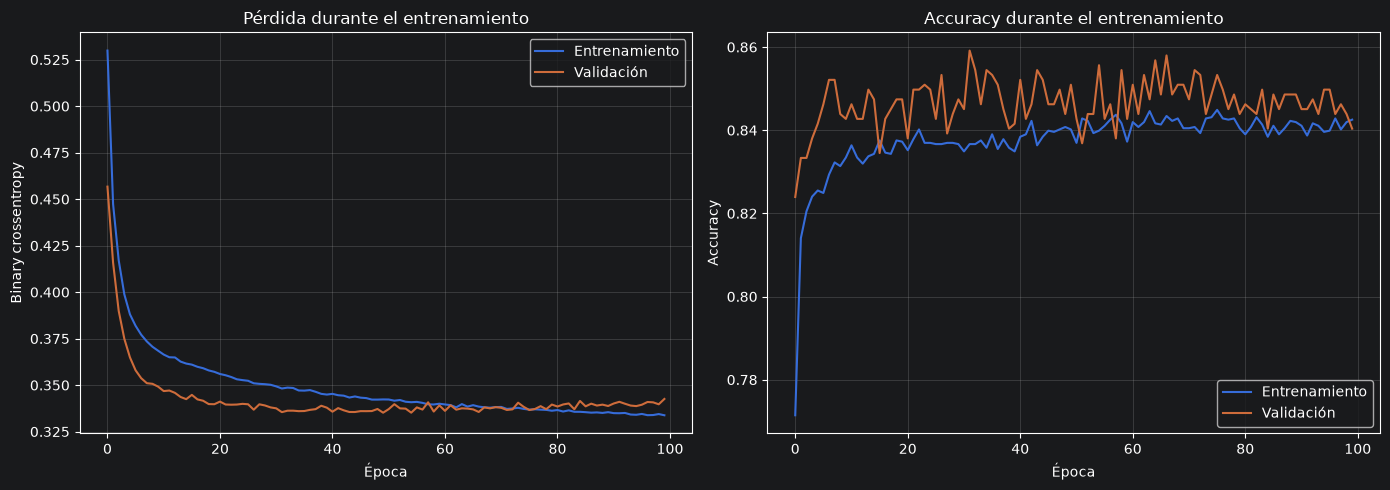

In [15]:
# Visualización de las curvas de aprendizaje

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de pérdida
axes[0].plot(
    history_all_12_6.history["loss"],
    label="Entrenamiento"
)
axes[0].plot(
    history_all_12_6.history["val_loss"],
    label="Validación"
)
axes[0].set_title("Pérdida durante el entrenamiento")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary crossentropy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Gráfico de accuracy
axes[1].plot(
    history_all_12_6.history["accuracy"],
    label="Entrenamiento"
)
axes[1].plot(
    history_all_12_6.history["val_accuracy"],
    label="Validación"
)
axes[1].set_title("Accuracy durante el entrenamiento")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5.3. Entrenamiento con EarlyStopping y comparación de resultados

In [16]:
# 5.3. Entrenamiento con EarlyStopping

# Crear una nueva instancia de la misma arquitectura
model_all_12_6_es = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(units=12, activation="relu"),
    Dense(units=6, activation="relu"),
    Dense(units=1, activation="sigmoid")
])

# Compilar el modelo
model_all_12_6_es.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Configurar EarlyStopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Entrenar el modelo
history_all_12_6_es = model_all_12_6_es.fit(
    X_train,
    y_train_classification,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

# Mostrar los resultados del entrenamiento
best_epoch = (
    np.argmin(history_all_12_6_es.history["val_loss"]) + 1
)

print("\nResultados del entrenamiento con EarlyStopping")
print("Épocas ejecutadas:", len(history_all_12_6_es.history["loss"]))
print("Mejor época:", best_epoch)
print(
    "Menor pérdida de validación:",
    round(min(history_all_12_6_es.history["val_loss"]), 4)
)

Epoch 1/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3499 - loss: 0.8467 - val_accuracy: 0.5939 - val_loss: 0.7129
Epoch 2/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6974 - loss: 0.6743 - val_accuracy: 0.7887 - val_loss: 0.6528
Epoch 3/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7952 - loss: 0.6359 - val_accuracy: 0.8192 - val_loss: 0.6212
Epoch 4/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8111 - loss: 0.6108 - val_accuracy: 0.8239 - val_loss: 0.5964
Epoch 5/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8137 - loss: 0.5897 - val_accuracy: 0.8286 - val_loss: 0.5748
Epoch 6/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8179 - loss: 0.5706 - val_accuracy: 0.8310 - val_loss: 0.5554
Epoch 7/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8202 - loss: 0.5533 - val_accuracy: 0.8369 - val_loss: 0.5379
Epoch 8/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8234 - loss: 0.5372 - val_accu

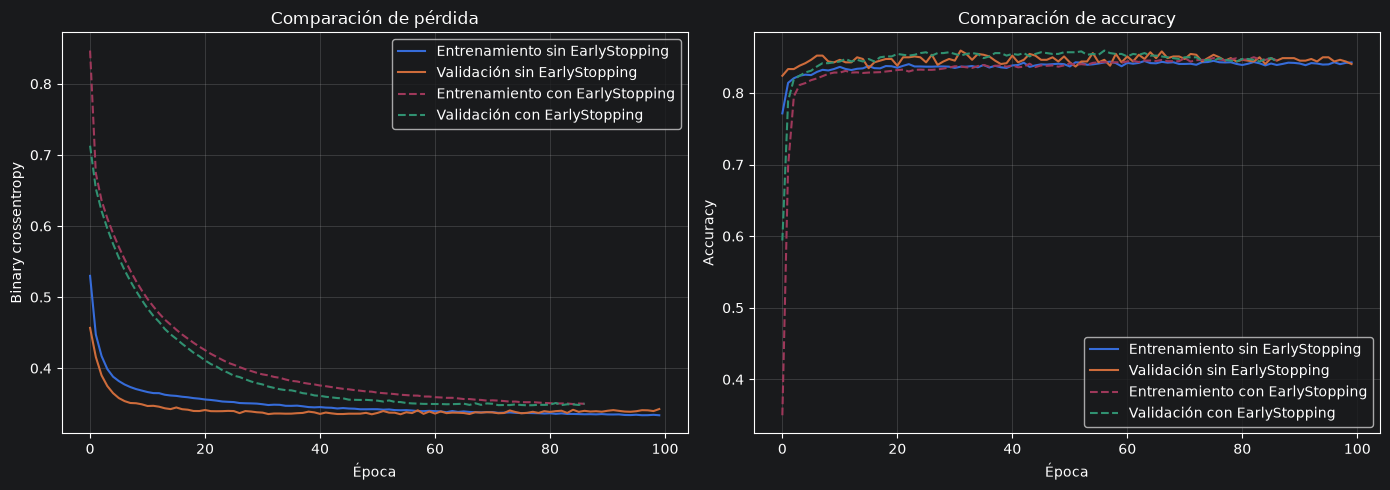

,Configuración,Épocas ejecutadas,Menor val_loss,Mayor val_accuracy
0,Sin EarlyStopping,100,0.3352,0.8592
1,Con EarlyStopping,87,0.3478,0.8592


In [17]:
# Comparar las curvas de aprendizaje

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pérdida
axes[0].plot(
    history_all_12_6.history["loss"],
    label="Entrenamiento sin EarlyStopping"
)
axes[0].plot(
    history_all_12_6.history["val_loss"],
    label="Validación sin EarlyStopping"
)
axes[0].plot(
    history_all_12_6_es.history["loss"],
    linestyle="--",
    label="Entrenamiento con EarlyStopping"
)
axes[0].plot(
    history_all_12_6_es.history["val_loss"],
    linestyle="--",
    label="Validación con EarlyStopping"
)

axes[0].set_title("Comparación de pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary crossentropy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(
    history_all_12_6.history["accuracy"],
    label="Entrenamiento sin EarlyStopping"
)
axes[1].plot(
    history_all_12_6.history["val_accuracy"],
    label="Validación sin EarlyStopping"
)
axes[1].plot(
    history_all_12_6_es.history["accuracy"],
    linestyle="--",
    label="Entrenamiento con EarlyStopping"
)
axes[1].plot(
    history_all_12_6_es.history["val_accuracy"],
    linestyle="--",
    label="Validación con EarlyStopping"
)

axes[1].set_title("Comparación de accuracy")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Comparar los resultados principales
comparison_early_stopping = pd.DataFrame({
    "Configuración": [
        "Sin EarlyStopping",
        "Con EarlyStopping"
    ],
    "Épocas ejecutadas": [
        len(history_all_12_6.history["loss"]),
        len(history_all_12_6_es.history["loss"])
    ],
    "Menor val_loss": [
        min(history_all_12_6.history["val_loss"]),
        min(history_all_12_6_es.history["val_loss"])
    ],
    "Mayor val_accuracy": [
        max(history_all_12_6.history["val_accuracy"]),
        max(history_all_12_6_es.history["val_accuracy"])
    ]
})

display(comparison_early_stopping.round(4))

### 5.4. Entrenamiento con Dropout y comparación de resultados

In [18]:
# 5.4. Entrenamiento con Dropout

# Construir una nueva ANN con la misma arquitectura
model_all_12_6_dropout = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(units=12, activation="relu"),
    Dropout(0.5),

    Dense(units=6, activation="relu"),
    Dropout(0.5),

    Dense(units=1, activation="sigmoid")
])

# Compilar el modelo
model_all_12_6_dropout.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# Configurar EarlyStopping
early_stopping_dropout = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Entrenar la ANN
history_all_12_6_dropout = model_all_12_6_dropout.fit(
    X_train,
    y_train_classification,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping_dropout],
    verbose=1
)

print("Épocas ejecutadas:",
      len(history_all_12_6_dropout.history["loss"]))

print("Menor pérdida de validación:",
      round(min(history_all_12_6_dropout.history["val_loss"]), 4))

print("Mayor accuracy de validación:",
      round(max(history_all_12_6_dropout.history["val_accuracy"]), 4))

Epoch 1/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.5834 - loss: 0.7960 - val_accuracy: 0.6960 - val_loss: 0.6293
Epoch 2/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7045 - loss: 0.6377 - val_accuracy: 0.8310 - val_loss: 0.5318
Epoch 3/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7644 - loss: 0.5775 - val_accuracy: 0.8286 - val_loss: 0.4790
Epoch 4/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7841 - loss: 0.5409 - val_accuracy: 0.8263 - val_loss: 0.4496
Epoch 5/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7873 - loss: 0.5151 - val_accuracy: 0.8263 - val_loss: 0.4274
Epoch 6/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7967 - loss: 0.5023 - val_accuracy: 0.8263 - val_loss: 0.4111
Epoch 7/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8029 - loss: 0.4894 - val_accuracy: 0.8263 - val_loss: 0.4033
Epoch 8/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8035 - loss: 0.4871 - val_accu

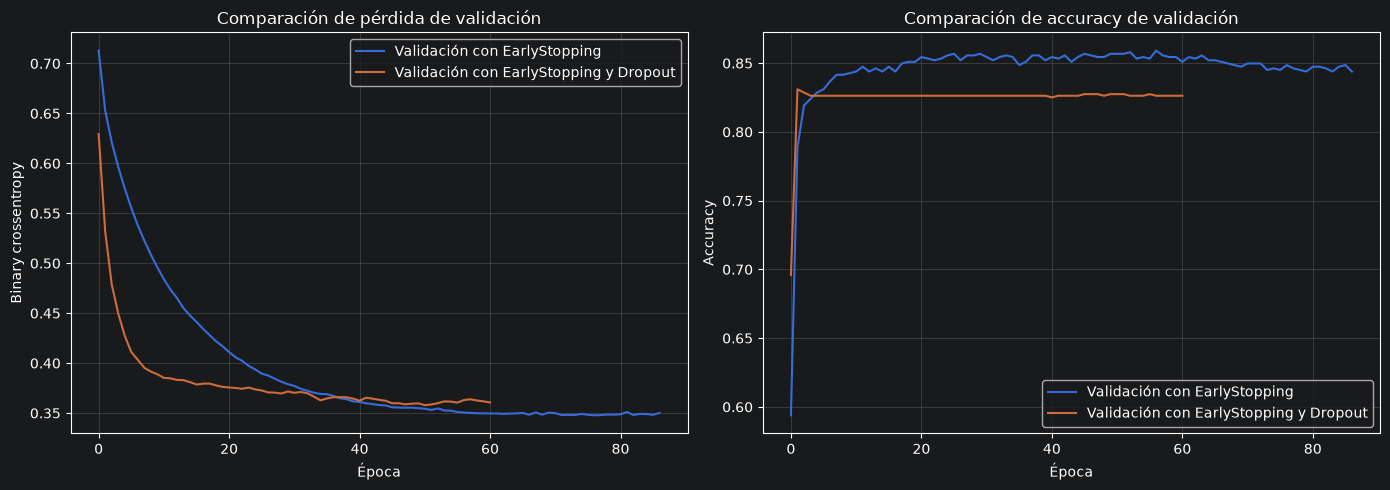

,Configuración,Épocas ejecutadas,Menor val_loss,Mayor val_accuracy
0,EarlyStopping,87,0.3478,0.8592
1,EarlyStopping + Dropout,61,0.3579,0.8310


In [19]:
# Comparación: EarlyStopping frente a EarlyStopping + Dropout

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Comparar pérdida
axes[0].plot(
    history_all_12_6_es.history["val_loss"],
    label="Validación con EarlyStopping"
)
axes[0].plot(
    history_all_12_6_dropout.history["val_loss"],
    label="Validación con EarlyStopping y Dropout"
)
axes[0].set_title("Comparación de pérdida de validación")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary crossentropy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Comparar accuracy
axes[1].plot(
    history_all_12_6_es.history["val_accuracy"],
    label="Validación con EarlyStopping"
)
axes[1].plot(
    history_all_12_6_dropout.history["val_accuracy"],
    label="Validación con EarlyStopping y Dropout"
)
axes[1].set_title("Comparación de accuracy de validación")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Resumen de los experimentos
comparison_dropout = pd.DataFrame({
    "Configuración": [
        "EarlyStopping",
        "EarlyStopping + Dropout"
    ],
    "Épocas ejecutadas": [
        len(history_all_12_6_es.history["loss"]),
        len(history_all_12_6_dropout.history["loss"])
    ],
    "Menor val_loss": [
        min(history_all_12_6_es.history["val_loss"]),
        min(history_all_12_6_dropout.history["val_loss"])
    ],
    "Mayor val_accuracy": [
        max(history_all_12_6_es.history["val_accuracy"]),
        max(history_all_12_6_dropout.history["val_accuracy"])
    ]
})

display(comparison_dropout.round(4))

In [25]:
**Análisis de resultados**

La incorporación de Dropout con una tasa de 0.5 no mejoró el rendimiento de validación de la arquitectura evaluada. La accuracy de validación se mantuvo aproximadamente en 82.6 %, por debajo del modelo entrenado con EarlyStopping sin Dropout, que alcanzó valores cercanos al 85 %.

Además, la pérdida de validación del modelo sin Dropout fue ligeramente menor al finalizar el entrenamiento. Estos resultados sugieren que Dropout podría ser demasiado fuerte para esta arquitectura. Se conservarán los resultados para compararlos con otras configuraciones.

SyntaxError: invalid syntax (1263736366.py, line 1)

### 5.5. Construcción de la arquitectura B (16 y 8 neuronas)

In [20]:
# 5.5. Construcción de la arquitectura B (16 y 8 neuronas)

model_all_16_8 = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(units=16, activation="relu"),
    Dense(units=8, activation="relu"),

    Dense(units=1, activation="sigmoid")
])

# Compilar el modelo
model_all_16_8.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Mostrar la arquitectura
model_all_16_8.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353 (1.38 KB)

 Trainable params: 353 (1.38 KB)

 Non-trainable params: 0 (0.00 B)

### 5.6. Entrenamiento y visualización de las curvas de aprendizaje

In [21]:
# 5.6. Entrenamiento de la arquitectura B (16 y 8 neuronas)

# Configurar EarlyStopping
early_stopping_16_8 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Entrenar el modelo
history_all_16_8 = model_all_16_8.fit(
    X_train,
    y_train_classification,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping_16_8],
    verbose=1
)

# Mostrar resultados del entrenamiento
best_epoch_16_8 = (
    np.argmin(history_all_16_8.history["val_loss"]) + 1
)

print("Épocas ejecutadas:",
      len(history_all_16_8.history["loss"]))

print("Mejor época:", best_epoch_16_8)

print("Menor pérdida de validación:",
      round(min(history_all_16_8.history["val_loss"]), 4))

print("Mayor accuracy de validación:",
      round(max(history_all_16_8.history["val_accuracy"]), 4))

Epoch 1/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.7098 - loss: 0.6098 - val_accuracy: 0.8181 - val_loss: 0.4656
Epoch 2/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8052 - loss: 0.4418 - val_accuracy: 0.8286 - val_loss: 0.3946
Epoch 3/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8190 - loss: 0.4034 - val_accuracy: 0.8369 - val_loss: 0.3810
Epoch 4/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8243 - loss: 0.3907 - val_accuracy: 0.8357 - val_loss: 0.3728
Epoch 5/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8243 - loss: 0.3840 - val_accuracy: 0.8427 - val_loss: 0.3671
Epoch 6/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8278 - loss: 0.3786 - val_accuracy: 0.8369 - val_loss: 0.3641
Epoch 7/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8267 - loss: 0.3747 - val_accuracy: 0.8415 - val_loss: 0.3620
Epoch 8/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8311 - loss: 0.3716 - val_acc

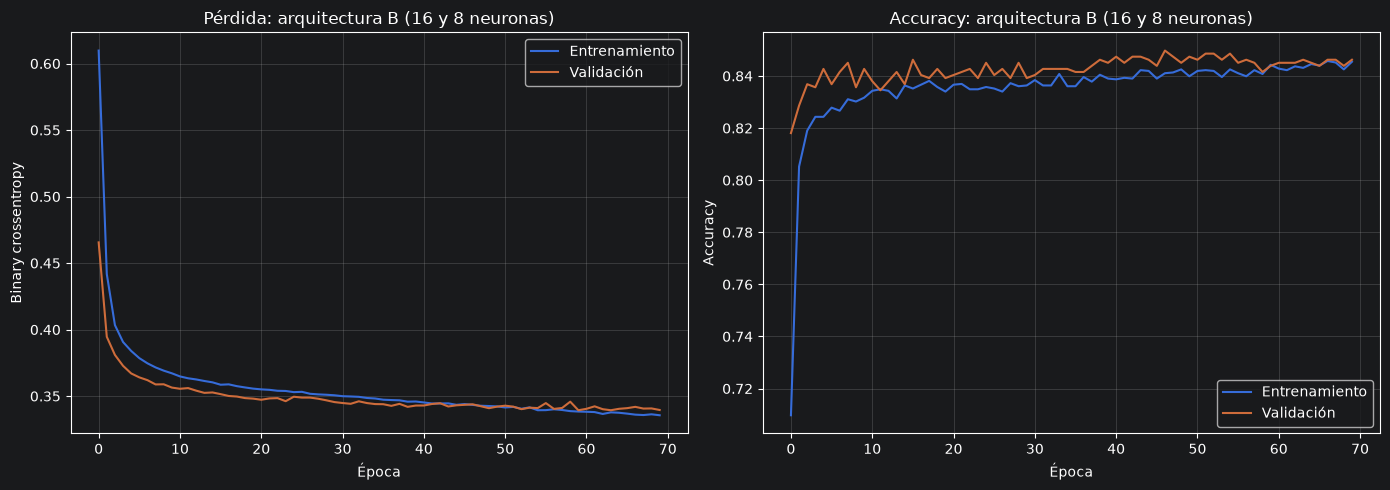

In [22]:
# Graficar las curvas de aprendizaje de la arquitectura B

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curva de pérdida
axes[0].plot(
    history_all_16_8.history["loss"],
    label="Entrenamiento"
)
axes[0].plot(
    history_all_16_8.history["val_loss"],
    label="Validación"
)
axes[0].set_title("Pérdida: arquitectura B (16 y 8 neuronas)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary crossentropy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Curva de accuracy
axes[1].plot(
    history_all_16_8.history["accuracy"],
    label="Entrenamiento"
)
axes[1].plot(
    history_all_16_8.history["val_accuracy"],
    label="Validación"
)
axes[1].set_title("Accuracy: arquitectura B (16 y 8 neuronas)")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5.7. Comparación de las arquitecturas A y B

In [23]:
# 5.7. Comparación de las arquitecturas A y B

def resumir_modelo(nombre, history):
    # Encontrar la época con menor pérdida de validación
    best_index = int(np.argmin(history.history["val_loss"]))

    return {
        "Arquitectura": nombre,
        "Épocas ejecutadas": len(history.history["loss"]),
        "Mejor época (menor val_loss)": best_index + 1,
        "Menor val_loss": history.history["val_loss"][best_index],
        "val_accuracy en la mejor época": history.history["val_accuracy"][best_index],
        "Mayor val_accuracy": max(history.history["val_accuracy"])
    }


comparison_architectures = pd.DataFrame([
    resumir_modelo("Arquitectura A (12 y 6)", history_all_12_6_es),
    resumir_modelo("Arquitectura B (16 y 8)", history_all_16_8)
])

display(comparison_architectures.round(4))

,Arquitectura,Épocas ejecutadas,Mejor época (menor val_loss),Menor val_loss,val_accuracy en la mejor época,Mayor val_accuracy
0,Arquitectura A (12 y 6),87,77,0.3478,0.8486,0.8592
1,Arquitectura B (16 y 8),70,60,0.3394,0.8439,0.8498


**Conclusiones preliminares del Modelo 1**

Las arquitecturas evaluadas presentaron resultados similares. La arquitectura A, con 12 y 6 neuronas ocultas, alcanzó una accuracy máxima de validación del 85.92 %, mientras que la arquitectura B, con 16 y 8 neuronas, obtuvo la menor pérdida de validación. EarlyStopping permitió reducir la cantidad de épocas de entrenamiento, mientras que Dropout con una tasa de 0.5 no mejoró la accuracy observada. Por ahora, no se ha determinado una configuración definitiva, ya que es necesario comparar las métricas de clasificación, especialmente precision, recall y F1-score, para identificar cuál reconoce mejor los vinos de calidad alta.

### 5.8. Evaluación de las configuraciones del Modelo 1

,Configuración,Accuracy,Precision (clase 1),Recall (clase 1),F1-score (clase 1)
0,Arquitectura A (12 y 6),0.8486,0.6118,0.3514,0.4464
1,Arquitectura A + Dropout,0.8275,0.6667,0.0135,0.0265
2,Arquitectura B (16 y 8),0.8439,0.5773,0.3784,0.4571


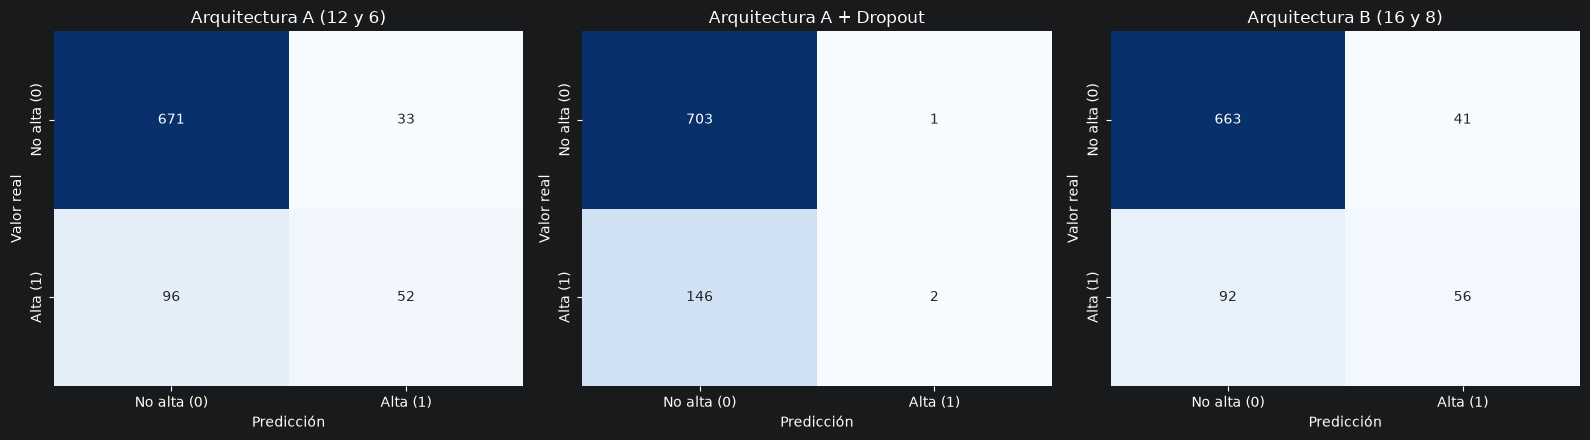


Reporte de clasificación: Arquitectura A (12 y 6)
                 precision    recall  f1-score   support

Calidad no alta       0.87      0.95      0.91       704
   Calidad alta       0.61      0.35      0.45       148

       accuracy                           0.85       852
      macro avg       0.74      0.65      0.68       852
   weighted avg       0.83      0.85      0.83       852


Reporte de clasificación: Arquitectura A + Dropout
                 precision    recall  f1-score   support

Calidad no alta       0.83      1.00      0.91       704
   Calidad alta       0.67      0.01      0.03       148

       accuracy                           0.83       852
      macro avg       0.75      0.51      0.47       852
   weighted avg       0.80      0.83      0.75       852


Reporte de clasificación: Arquitectura B (16 y 8)
                 precision    recall  f1-score   support

Calidad no alta       0.88      0.94      0.91       704
   Calidad alta       0.58      0.38     

In [28]:
# 5.8. Evaluación de las configuraciones del Modelo 1
# Usamos la misma partición de validación que validation_split=0.2

split_at = int(len(X_train) * 0.8)

X_val_model1 = X_train.iloc[split_at:].copy()
y_val_model1 = y_train_classification.iloc[split_at:].copy()

# Modelos que vamos a comparar
models_model1 = {
    "Arquitectura A (12 y 6)": model_all_12_6_es,
    "Arquitectura A + Dropout": model_all_12_6_dropout,
    "Arquitectura B (16 y 8)": model_all_16_8
}

results_model1 = []
confusion_matrices_model1 = {}

for name, model in models_model1.items():
    # Obtener probabilidades y convertirlas en clases
    probabilities = model.predict(X_val_model1, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    # Calcular métricas para la clase positiva (calidad alta = 1)
    results_model1.append({
        "Configuración": name,
        "Accuracy": accuracy_score(y_val_model1, predictions),
        "Precision (clase 1)": precision_score(
            y_val_model1, predictions, pos_label=1, zero_division=0
        ),
        "Recall (clase 1)": recall_score(
            y_val_model1, predictions, pos_label=1, zero_division=0
        ),
        "F1-score (clase 1)": f1_score(
            y_val_model1, predictions, pos_label=1, zero_division=0
        )
    })

    confusion_matrices_model1[name] = confusion_matrix(
        y_val_model1, predictions, labels=[0, 1]
    )

# Mostrar la comparación de métricas
results_model1_df = pd.DataFrame(results_model1)
display(results_model1_df.round(4))

# Mostrar las matrices de confusión
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, matrix) in zip(axes, confusion_matrices_model1.items()):
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["No alta (0)", "Alta (1)"],
        yticklabels=["No alta (0)", "Alta (1)"],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")

plt.tight_layout()
plt.show()

# Mostrar el reporte detallado de clasificación
for name, model in models_model1.items():
    predictions = (
        model.predict(X_val_model1, verbose=0).ravel() >= 0.5
    ).astype(int)

    print(f"\nReporte de clasificación: {name}")
    print(classification_report(
        y_val_model1,
        predictions,
        labels=[0, 1],
        target_names=["Calidad no alta", "Calidad alta"],
        zero_division=0
    ))

## 6. Construcción, entrenamiento y evaluación de la ANN con variables seleccionadas

### 6.1. Construcción de la arquitectura A (6 y 3 neuronas)

In [36]:
# 6.1. Construcción de la arquitectura A (6 y 3 neuronas)

# Cantidad de variables seleccionadas
num_neuronas_selected = X_train_selected.shape[1]

# Crear la red neuronal
model_selected_6_3 = Sequential([
    Input(shape=(num_neuronas_selected,)),

    Dense(
        units=num_neuronas_selected,
        activation="relu"
    ),

    Dense(
        units=int(np.round(num_neuronas_selected / 2)),
        activation="relu"
    ),

    Dense(units=1, activation="sigmoid")
])

# Compilar el modelo
model_selected_6_3.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Mostrar la arquitectura
model_selected_6_3.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 6)              │            42 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 3)              │            21 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

### 6.2. Entrenamiento inicial y visualización de las curvas de aprendizaje

In [42]:
# 6.2. Entrenamiento inicial del Modelo 2 (6 y 3 neuronas)

history_selected_6_3 = model_selected_6_3.fit(
    X_train_selected,
    y_train_classification,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

print("Épocas ejecutadas:",
      len(history_selected_6_3.history["loss"]))

print("Menor pérdida de validación:",
      round(min(history_selected_6_3.history["val_loss"]), 4))

print("Mayor accuracy de validación:",
      round(max(history_selected_6_3.history["val_accuracy"]), 4))

Epoch 1/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7039 - loss: 0.6554 - val_accuracy: 0.8016 - val_loss: 0.5979
Epoch 2/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8011 - loss: 0.5721 - val_accuracy: 0.8263 - val_loss: 0.5219
Epoch 3/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8064 - loss: 0.5007 - val_accuracy: 0.8263 - val_loss: 0.4718
Epoch 4/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8064 - loss: 0.4648 - val_accuracy: 0.8263 - val_loss: 0.4449
Epoch 5/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8064 - loss: 0.4444 - val_accuracy: 0.8263 - val_loss: 0.4260
Epoch 6/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8064 - loss: 0.4300 - val_accuracy: 0.8263 - val_loss: 0.4126
Epoch 7/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8073 - loss: 0.4185 - val_accuracy: 0.8286 - val_loss: 0.4017
Epoch 8/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8085 - loss: 0.4091 - val_accu

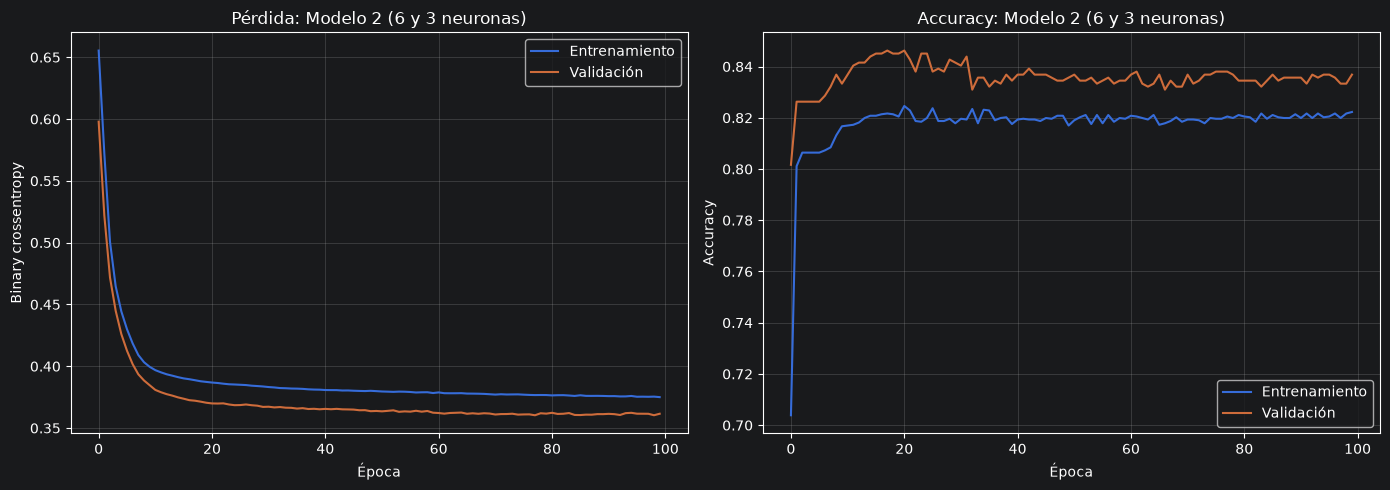

In [43]:
# Visualización de las curvas de aprendizaje del Modelo 2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de pérdida
axes[0].plot(
    history_selected_6_3.history["loss"],
    label="Entrenamiento"
)
axes[0].plot(
    history_selected_6_3.history["val_loss"],
    label="Validación"
)
axes[0].set_title("Pérdida: Modelo 2 (6 y 3 neuronas)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary crossentropy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Gráfico de accuracy
axes[1].plot(
    history_selected_6_3.history["accuracy"],
    label="Entrenamiento"
)
axes[1].plot(
    history_selected_6_3.history["val_accuracy"],
    label="Validación"
)
axes[1].set_title("Accuracy: Modelo 2 (6 y 3 neuronas)")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 6.3. Entrenamiento con EarlyStopping y comparación de resultados

In [44]:
# 6.3. Entrenamiento con EarlyStopping

# Crear una nueva ANN con la misma arquitectura
model_selected_6_3_es = Sequential([
    Input(shape=(X_train_selected.shape[1],)),
    Dense(units=6, activation="relu"),
    Dense(units=3, activation="relu"),
    Dense(units=1, activation="sigmoid")
])

# Compilar el modelo
model_selected_6_3_es.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Configurar EarlyStopping
early_stopping_selected = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Entrenar la red
history_selected_6_3_es = model_selected_6_3_es.fit(
    X_train_selected,
    y_train_classification,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping_selected],
    verbose=1
)

# Mostrar resultados
best_epoch_selected = (
    np.argmin(history_selected_6_3_es.history["val_loss"]) + 1
)

print("Épocas ejecutadas:",
      len(history_selected_6_3_es.history["loss"]))

print("Mejor época:", best_epoch_selected)

print("Menor pérdida de validación:",
      round(min(history_selected_6_3_es.history["val_loss"]), 4))

print("Mayor accuracy de validación:",
      round(max(history_selected_6_3_es.history["val_accuracy"]), 4))

Epoch 1/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4703 - loss: 0.8293 - val_accuracy: 0.6890 - val_loss: 0.6875
Epoch 2/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7808 - loss: 0.6064 - val_accuracy: 0.8251 - val_loss: 0.5144
Epoch 3/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8055 - loss: 0.4977 - val_accuracy: 0.8298 - val_loss: 0.4378
Epoch 4/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8111 - loss: 0.4417 - val_accuracy: 0.8357 - val_loss: 0.3978
Epoch 5/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8137 - loss: 0.4139 - val_accuracy: 0.8380 - val_loss: 0.3814
Epoch 6/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8173 - loss: 0.4025 - val_accuracy: 0.8404 - val_loss: 0.3758
Epoch 7/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8158 - loss: 0.3979 - val_accuracy: 0.8451 - val_loss: 0.3724
Epoch 8/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8149 - loss: 0.3954 - val_accu

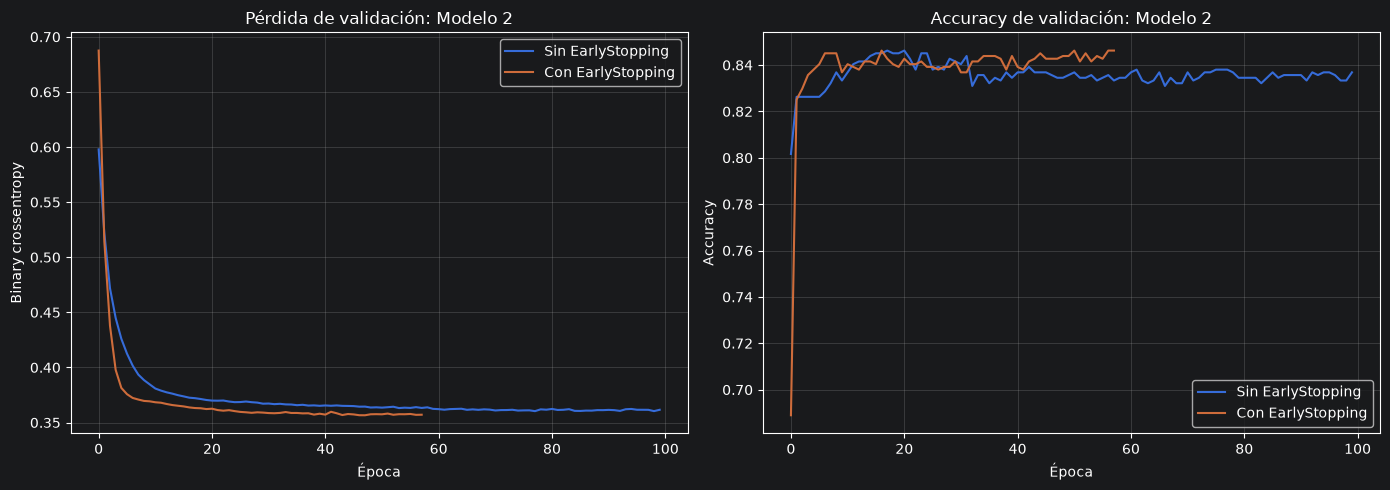

In [45]:
# Comparar el entrenamiento inicial con EarlyStopping

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Comparación de pérdida de validación
axes[0].plot(
    history_selected_6_3.history["val_loss"],
    label="Sin EarlyStopping"
)
axes[0].plot(
    history_selected_6_3_es.history["val_loss"],
    label="Con EarlyStopping"
)
axes[0].set_title("Pérdida de validación: Modelo 2")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary crossentropy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Comparación de accuracy de validación
axes[1].plot(
    history_selected_6_3.history["val_accuracy"],
    label="Sin EarlyStopping"
)
axes[1].plot(
    history_selected_6_3_es.history["val_accuracy"],
    label="Con EarlyStopping"
)
axes[1].set_title("Accuracy de validación: Modelo 2")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 6.4. Entrenamiento con Dropout y comparación de resultados

In [46]:
# 6.4. Entrenamiento del Modelo 2 con Dropout

# Construir una nueva ANN con Dropout
model_selected_6_3_dropout = Sequential([
    Input(shape=(X_train_selected.shape[1],)),

    Dense(units=6, activation="relu"),
    Dropout(0.5),

    Dense(units=3, activation="relu"),
    Dropout(0.5),

    Dense(units=1, activation="sigmoid")
])

# Compilar el modelo
model_selected_6_3_dropout.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Configurar EarlyStopping
early_stopping_selected_dropout = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Entrenar el modelo
history_selected_6_3_dropout = model_selected_6_3_dropout.fit(
    X_train_selected,
    y_train_classification,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping_selected_dropout],
    verbose=1
)

# Mostrar resultados
print("Épocas ejecutadas:",
      len(history_selected_6_3_dropout.history["loss"]))

print("Menor pérdida de validación:",
      round(min(history_selected_6_3_dropout.history["val_loss"]), 4))

print("Mayor accuracy de validación:",
      round(max(history_selected_6_3_dropout.history["val_accuracy"]), 4))

Epoch 1/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5690 - loss: 0.8421 - val_accuracy: 0.5904 - val_loss: 0.7098
Epoch 2/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6739 - loss: 0.7166 - val_accuracy: 0.7500 - val_loss: 0.6520
Epoch 3/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7391 - loss: 0.6583 - val_accuracy: 0.8263 - val_loss: 0.6171
Epoch 4/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7709 - loss: 0.6214 - val_accuracy: 0.8263 - val_loss: 0.5926
Epoch 5/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7894 - loss: 0.5993 - val_accuracy: 0.8263 - val_loss: 0.5731
Epoch 6/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8020 - loss: 0.5780 - val_accuracy: 0.8263 - val_loss: 0.5568
Epoch 7/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8049 - loss: 0.5629 - val_accuracy: 0.8263 - val_loss: 0.5430
Epoch 8/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8041 - loss: 0.5505 - val_accu

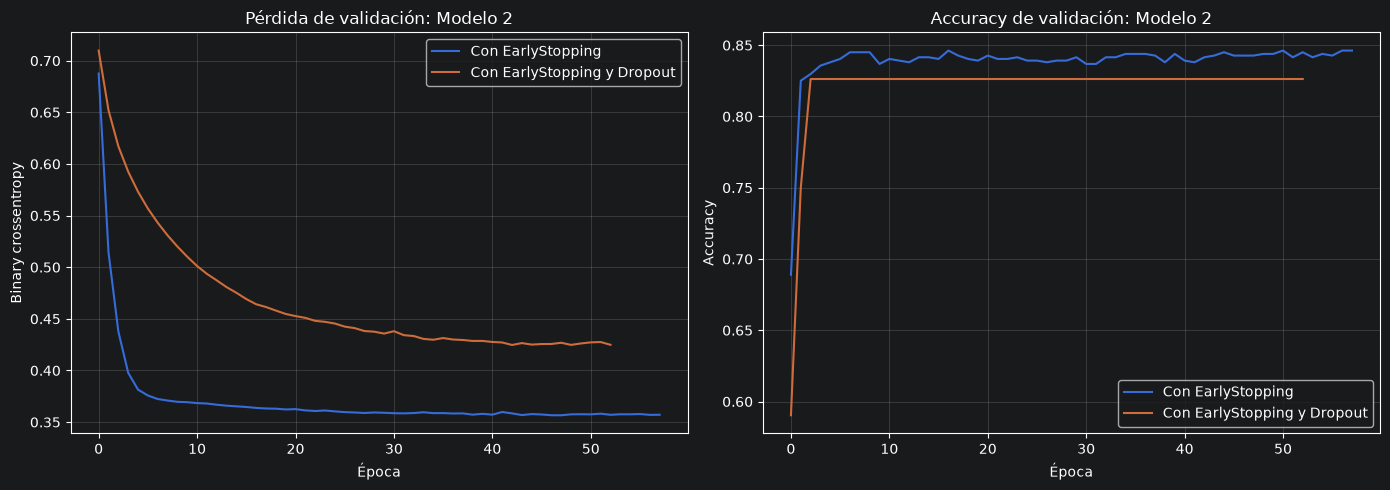

,Configuración,Épocas ejecutadas,Menor val_loss,Mayor val_accuracy
0,EarlyStopping,58,0.3566,0.8462
1,EarlyStopping + Dropout,53,0.4247,0.8263


In [47]:
# Comparar EarlyStopping frente a EarlyStopping + Dropout

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pérdida de validación
axes[0].plot(
    history_selected_6_3_es.history["val_loss"],
    label="Con EarlyStopping"
)
axes[0].plot(
    history_selected_6_3_dropout.history["val_loss"],
    label="Con EarlyStopping y Dropout"
)
axes[0].set_title("Pérdida de validación: Modelo 2")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary crossentropy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy de validación
axes[1].plot(
    history_selected_6_3_es.history["val_accuracy"],
    label="Con EarlyStopping"
)
axes[1].plot(
    history_selected_6_3_dropout.history["val_accuracy"],
    label="Con EarlyStopping y Dropout"
)
axes[1].set_title("Accuracy de validación: Modelo 2")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Tabla comparativa
comparison_dropout_model2 = pd.DataFrame({
    "Configuración": [
        "EarlyStopping",
        "EarlyStopping + Dropout"
    ],
    "Épocas ejecutadas": [
        len(history_selected_6_3_es.history["loss"]),
        len(history_selected_6_3_dropout.history["loss"])
    ],
    "Menor val_loss": [
        min(history_selected_6_3_es.history["val_loss"]),
        min(history_selected_6_3_dropout.history["val_loss"])
    ],
    "Mayor val_accuracy": [
        max(history_selected_6_3_es.history["val_accuracy"]),
        max(history_selected_6_3_dropout.history["val_accuracy"])
    ]
})

display(comparison_dropout_model2.round(4))

**Conclusiones de la arquitectura A (6 y 3 neuronas)**

La arquitectura de 6 y 3 neuronas mostró un mejor rendimiento con EarlyStopping que con Dropout de 0.5. Sin Dropout, alcanzó una accuracy máxima de validación del 84.62 % y una pérdida mínima de 0.3566. Con Dropout, la accuracy se mantuvo en 82.63 % y la pérdida mínima fue de 0.4247. Por lo tanto, Dropout no mejoró el aprendizaje en esta configuración y se conservará este resultado para la comparación final del Modelo 2.

### 6.5. Construcción de la arquitectura B (16 y 8 neuronas)

In [50]:
# 6.5. Construcción de la arquitectura B (16 y 8 neuronas)

model_selected_16_8 = Sequential([
    Input(shape=(X_train_selected.shape[1],)),

    Dense(units=16, activation="relu"),
    Dense(units=8, activation="relu"),

    Dense(units=1, activation="sigmoid")
])

# Compilar el modelo
model_selected_16_8.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Mostrar la arquitectura
model_selected_16_8.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 16)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257 (1.00 KB)

 Trainable params: 257 (1.00 KB)

 Non-trainable params: 0 (0.00 B)

### 6.6. Entrenamiento y visualización de las curvas de aprendizaje

In [51]:
# 6.6. Entrenamiento de la arquitectura B (16 y 8 neuronas)

# Configurar EarlyStopping
early_stopping_selected_16_8 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Entrenar el modelo
history_selected_16_8 = model_selected_16_8.fit(
    X_train_selected,
    y_train_classification,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping_selected_16_8],
    verbose=1
)

# Mostrar resultados del entrenamiento
best_epoch_selected_16_8 = (
    np.argmin(history_selected_16_8.history["val_loss"]) + 1
)

print("Épocas ejecutadas:",
      len(history_selected_16_8.history["loss"]))

print("Mejor época:", best_epoch_selected_16_8)

print("Menor pérdida de validación:",
      round(min(history_selected_16_8.history["val_loss"]), 4))

print("Mayor accuracy de validación:",
      round(max(history_selected_16_8.history["val_accuracy"]), 4))

Epoch 1/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5394 - loss: 0.6947 - val_accuracy: 0.8157 - val_loss: 0.5355
Epoch 2/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8052 - loss: 0.4709 - val_accuracy: 0.8404 - val_loss: 0.3974
Epoch 3/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8184 - loss: 0.4024 - val_accuracy: 0.8404 - val_loss: 0.3774
Epoch 4/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8226 - loss: 0.3919 - val_accuracy: 0.8369 - val_loss: 0.3732
Epoch 5/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8220 - loss: 0.3886 - val_accuracy: 0.8380 - val_loss: 0.3701
Epoch 6/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8229 - loss: 0.3864 - val_accuracy: 0.8369 - val_loss: 0.3679
Epoch 7/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8231 - loss: 0.3848 - val_accuracy: 0.8380 - val_loss: 0.3659
Epoch 8/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8264 - loss: 0.3836 - val_accu

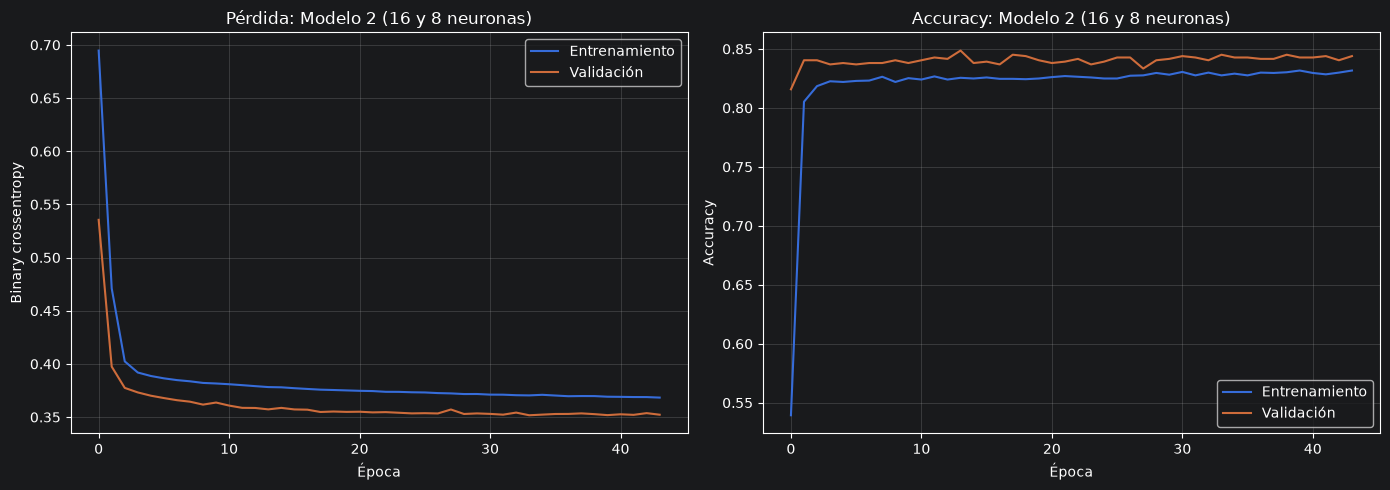

In [52]:
# Graficar las curvas de aprendizaje de la arquitectura B

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curva de pérdida
axes[0].plot(
    history_selected_16_8.history["loss"],
    label="Entrenamiento"
)
axes[0].plot(
    history_selected_16_8.history["val_loss"],
    label="Validación"
)
axes[0].set_title("Pérdida: Modelo 2 (16 y 8 neuronas)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary crossentropy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Curva de accuracy
axes[1].plot(
    history_selected_16_8.history["accuracy"],
    label="Entrenamiento"
)
axes[1].plot(
    history_selected_16_8.history["val_accuracy"],
    label="Validación"
)
axes[1].set_title("Accuracy: Modelo 2 (16 y 8 neuronas)")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 6.7. Comparación de las arquitecturas A y B

,Arquitectura,Épocas ejecutadas,Mejor época,Menor val_loss,val_accuracy en mejor época,Máxima val_accuracy
0,Arquitectura A (6 y 3),58,48,0.3566,0.8427,0.8462
1,Arquitectura B (16 y 8),44,34,0.3517,0.8451,0.8486


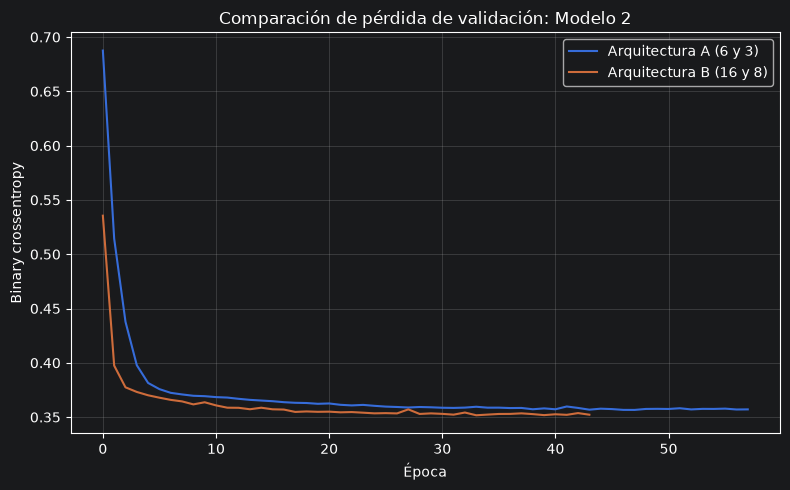

In [53]:
# 6.7. Comparación de las arquitecturas A y B del Modelo 2

def resumen_arquitectura(nombre, history):
    best_index = int(np.argmin(history.history["val_loss"]))

    return {
        "Arquitectura": nombre,
        "Épocas ejecutadas": len(history.history["loss"]),
        "Mejor época": best_index + 1,
        "Menor val_loss": history.history["val_loss"][best_index],
        "val_accuracy en mejor época": history.history["val_accuracy"][best_index],
        "Máxima val_accuracy": max(history.history["val_accuracy"])
    }


comparison_model2 = pd.DataFrame([
    resumen_arquitectura(
        "Arquitectura A (6 y 3)",
        history_selected_6_3_es
    ),
    resumen_arquitectura(
        "Arquitectura B (16 y 8)",
        history_selected_16_8
    )
])

display(comparison_model2.round(4))

# Comparar las curvas de pérdida de validación
plt.figure(figsize=(8, 5))

plt.plot(
    history_selected_6_3_es.history["val_loss"],
    label="Arquitectura A (6 y 3)"
)
plt.plot(
    history_selected_16_8.history["val_loss"],
    label="Arquitectura B (16 y 8)"
)

plt.title("Comparación de pérdida de validación: Modelo 2")
plt.xlabel("Época")
plt.ylabel("Binary crossentropy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 6.8. Evaluación de las configuraciones del Modelo 2

,Configuración,Accuracy,Precision (clase 1),Recall (clase 1),F1-score (clase 1)
0,Arquitectura A (6 y 3),0.8427,0.5946,0.2973,0.3964
1,Arquitectura A + Dropout,0.8263,0.0000,0.0000,0.0000
2,Arquitectura B (16 y 8),0.8451,0.5976,0.3311,0.4261


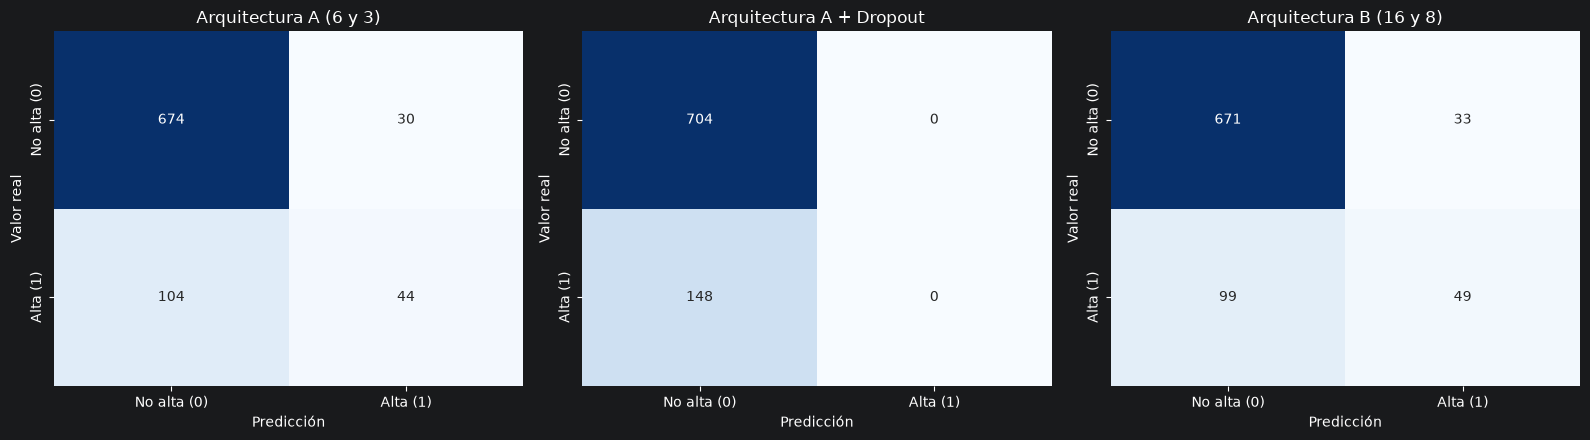


Reporte de clasificación: Arquitectura A (6 y 3)
                 precision    recall  f1-score   support

Calidad no alta       0.87      0.96      0.91       704
   Calidad alta       0.59      0.30      0.40       148

       accuracy                           0.84       852
      macro avg       0.73      0.63      0.65       852
   weighted avg       0.82      0.84      0.82       852


Reporte de clasificación: Arquitectura A + Dropout
                 precision    recall  f1-score   support

Calidad no alta       0.83      1.00      0.90       704
   Calidad alta       0.00      0.00      0.00       148

       accuracy                           0.83       852
      macro avg       0.41      0.50      0.45       852
   weighted avg       0.68      0.83      0.75       852


Reporte de clasificación: Arquitectura B (16 y 8)
                 precision    recall  f1-score   support

Calidad no alta       0.87      0.95      0.91       704
   Calidad alta       0.60      0.33      

In [54]:
# 6.8. Evaluación de las configuraciones del Modelo 2

# Recuperar el 20 % final de los datos de entrenamiento,
# correspondiente a validation_split=0.2 de Keras
split_at = int(len(X_train) * 0.8)

X_val_model2 = X_train_selected.iloc[split_at:].copy()
y_val_model2 = y_train_classification.iloc[split_at:].copy()

# Configuraciones a comparar
models_model2 = {
    "Arquitectura A (6 y 3)": model_selected_6_3_es,
    "Arquitectura A + Dropout": model_selected_6_3_dropout,
    "Arquitectura B (16 y 8)": model_selected_16_8
}

results_model2 = []
confusion_matrices_model2 = {}

for name, model in models_model2.items():

    # Predecir probabilidades y convertirlas en clases
    probabilities = model.predict(X_val_model2, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    # Calcular métricas
    results_model2.append({
        "Configuración": name,
        "Accuracy": accuracy_score(y_val_model2, predictions),
        "Precision (clase 1)": precision_score(
            y_val_model2, predictions, pos_label=1, zero_division=0
        ),
        "Recall (clase 1)": recall_score(
            y_val_model2, predictions, pos_label=1, zero_division=0
        ),
        "F1-score (clase 1)": f1_score(
            y_val_model2, predictions, pos_label=1, zero_division=0
        )
    })

    confusion_matrices_model2[name] = confusion_matrix(
        y_val_model2, predictions, labels=[0, 1]
    )

# Mostrar la tabla de resultados
results_model2_df = pd.DataFrame(results_model2)
display(results_model2_df.round(4))

# Mostrar las matrices de confusión
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, matrix) in zip(
    axes, confusion_matrices_model2.items()
):
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["No alta (0)", "Alta (1)"],
        yticklabels=["No alta (0)", "Alta (1)"],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")

plt.tight_layout()
plt.show()

# Informes detallados por configuración
for name, model in models_model2.items():
    predictions = (
        model.predict(X_val_model2, verbose=0).ravel() >= 0.5
    ).astype(int)

    print(f"\nReporte de clasificación: {name}")
    print(classification_report(
        y_val_model2,
        predictions,
        labels=[0, 1],
        target_names=["Calidad no alta", "Calidad alta"],
        zero_division=0
    ))

## 7. Comparación final de los mejores modelos

,Accuracy,Precision (clase 1),Recall (clase 1),F1-score (clase 1)
Modelo,,,,
Modelo 1: todas las variables,0.8318,0.5966,0.3515,0.4424
Modelo 2: variables seleccionadas,0.8271,0.6098,0.2475,0.3521


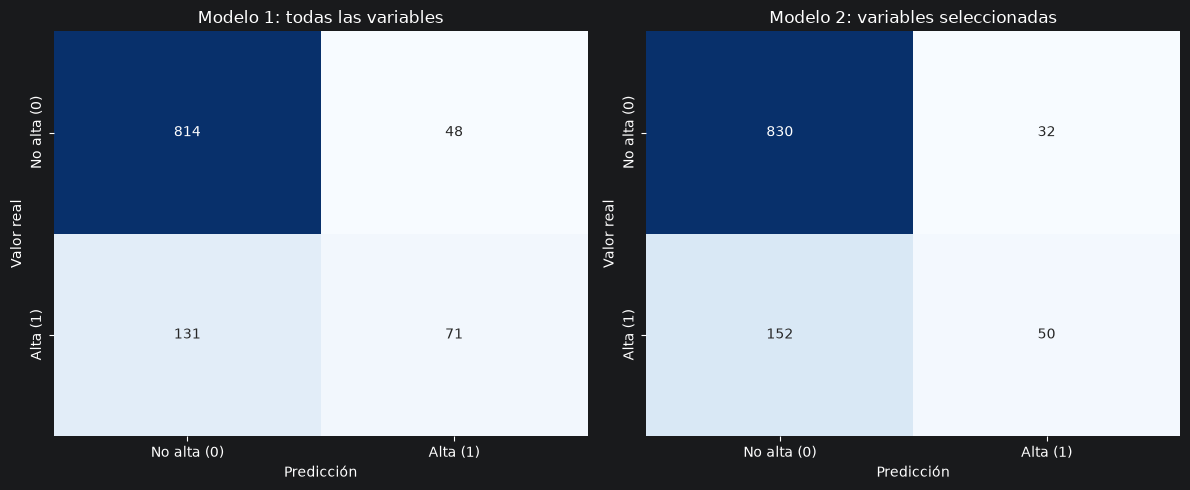


Reporte de clasificación: Modelo 1: todas las variables
                 precision    recall  f1-score   support

Calidad no alta       0.86      0.94      0.90       862
   Calidad alta       0.60      0.35      0.44       202

       accuracy                           0.83      1064
      macro avg       0.73      0.65      0.67      1064
   weighted avg       0.81      0.83      0.81      1064


Reporte de clasificación: Modelo 2: variables seleccionadas
                 precision    recall  f1-score   support

Calidad no alta       0.85      0.96      0.90       862
   Calidad alta       0.61      0.25      0.35       202

       accuracy                           0.83      1064
      macro avg       0.73      0.61      0.63      1064
   weighted avg       0.80      0.83      0.80      1064



In [56]:
# 7. Comparación final de los mejores modelos

# Configuraciones seleccionadas durante la validación
best_models = {
    "Modelo 1: todas las variables": (
        model_all_16_8,
        X_test
    ),
    "Modelo 2: variables seleccionadas": (
        model_selected_16_8,
        X_test_selected
    )
}

results_final = []
confusion_matrices_final = {}

for name, (model, X_evaluation) in best_models.items():

    # Predecir probabilidades y clasificarlas con umbral 0.5
    probabilities = model.predict(
        X_evaluation, verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    # Calcular métricas
    results_final.append({
        "Modelo": name,
        "Accuracy": accuracy_score(
            y_test_classification, predictions
        ),
        "Precision (clase 1)": precision_score(
            y_test_classification,
            predictions,
            pos_label=1,
            zero_division=0
        ),
        "Recall (clase 1)": recall_score(
            y_test_classification,
            predictions,
            pos_label=1,
            zero_division=0
        ),
        "F1-score (clase 1)": f1_score(
            y_test_classification,
            predictions,
            pos_label=1,
            zero_division=0
        )
    })

    # Guardar matriz de confusión
    confusion_matrices_final[name] = confusion_matrix(
        y_test_classification,
        predictions,
        labels=[0, 1]
    )

# Mostrar tabla comparativa
results_final_df = pd.DataFrame(results_final)

display(
    results_final_df
    .set_index("Modelo")
    .round(4)
)

# Graficar matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, matrix) in zip(
    axes, confusion_matrices_final.items()
):
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["No alta (0)", "Alta (1)"],
        yticklabels=["No alta (0)", "Alta (1)"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")

plt.tight_layout()
plt.show()

# Mostrar reportes detallados
for name, (model, X_evaluation) in best_models.items():
    predictions = (
        model.predict(X_evaluation, verbose=0).ravel() >= 0.5
    ).astype(int)

    print(f"\nReporte de clasificación: {name}")
    print(classification_report(
        y_test_classification,
        predictions,
        labels=[0, 1],
        target_names=["Calidad no alta", "Calidad alta"],
        zero_division=0
    ))

## 8. Conclusiones finales

Se compararon dos redes neuronales artificiales para clasificar la calidad del vino. El Modelo 1 utilizó las 12 variables predictoras, mientras que el Modelo 2 empleó seis variables seleccionadas mediante el análisis de correlación.

En el conjunto de prueba, ambos modelos alcanzaron una accuracy del 83 %. Sin embargo, el Modelo 1 obtuvo un recall del 35 % y un F1-score de 0.44 para la clase de calidad alta, superando al Modelo 2, que alcanzó un recall del 25 % y un F1-score de 0.35.

Por estos resultados, se selecciona provisionalmente el Modelo 1 como la mejor configuración evaluada, debido a su mayor capacidad para identificar vinos de calidad alta. No obstante, ambos modelos presentan limitaciones en la detección de esta clase, por lo que sería conveniente investigar estrategias para mejorar su rendimiento.

## 9. Investigación de estrategias para mejorar la clasificación de vinos de calidad alta

## 9. Modelo final seleccionado: ANN con ponderación moderada de clases

Epoch 1/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.7682 - loss: 0.7281 - val_accuracy: 0.8005 - val_loss: 0.4897
Epoch 2/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7976 - loss: 0.6243 - val_accuracy: 0.8028 - val_loss: 0.4274
Epoch 3/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7926 - loss: 0.5841 - val_accuracy: 0.7934 - val_loss: 0.4171
Epoch 4/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7961 - loss: 0.5690 - val_accuracy: 0.7911 - val_loss: 0.4178
Epoch 5/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7955 - loss: 0.5610 - val_accuracy: 0.7793 - val_loss: 0.4141
Epoch 6/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7935 - loss: 0.5565 - val_accuracy: 0.7923 - val_loss: 0.4037
Epoch 7/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7970 - loss: 0.5512 - val_accuracy: 0.8028 - val_loss: 0.3962
Epoch 8/100
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7985 - loss: 0.5479 - val_accu

,Accuracy,Precision (calidad alta),Recall (calidad alta),F1-score (calidad alta)
0,0.8102,0.5,0.5743,0.5346



Reporte de clasificación:
                 precision    recall  f1-score   support

Calidad no alta       0.90      0.87      0.88       862
   Calidad alta       0.50      0.57      0.53       202

       accuracy                           0.81      1064
      macro avg       0.70      0.72      0.71      1064
   weighted avg       0.82      0.81      0.82      1064



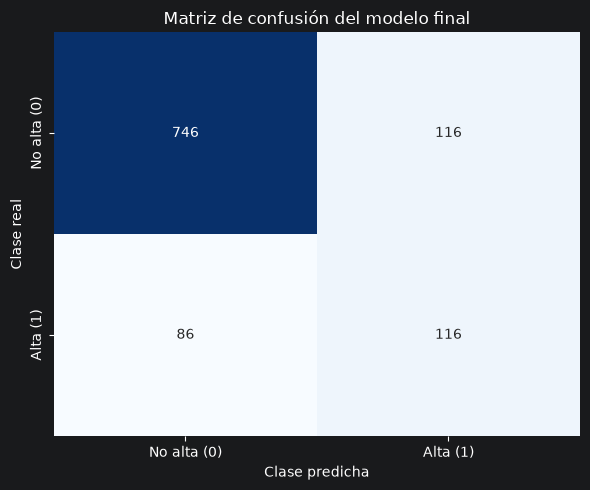

In [63]:
# 9. Entrenamiento del modelo seleccionado

# Construir la ANN con todas las variables
model_final = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

# Compilar la red neuronal
model_final.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Detener el entrenamiento cuando la validación deje de mejorar
early_stopping_final = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Entrenar con ponderación moderada de clases
history_final = model_final.fit(
    X_train,
    y_train_classification,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    class_weight={0: 1.0, 1: 2.0},
    callbacks=[early_stopping_final],
    verbose=1
)

print("Épocas ejecutadas:", len(history_final.history["loss"]))

# Evaluación final con datos de prueba
test_probabilities = model_final.predict(X_test, verbose=0).ravel()
test_predictions = (test_probabilities >= 0.5).astype(int)

# Calcular métricas
final_metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test_classification, test_predictions),
    "Precision (calidad alta)": precision_score(
        y_test_classification, test_predictions, zero_division=0
    ),
    "Recall (calidad alta)": recall_score(
        y_test_classification, test_predictions, zero_division=0
    ),
    "F1-score (calidad alta)": f1_score(
        y_test_classification, test_predictions, zero_division=0
    )
}])

print("\nResultados finales en el conjunto de prueba:")
display(final_metrics.round(4))

# Mostrar el reporte de clasificación
print("\nReporte de clasificación:")
print(classification_report(
    y_test_classification,
    test_predictions,
    labels=[0, 1],
    target_names=["Calidad no alta", "Calidad alta"],
    zero_division=0
))

# Mostrar la matriz de confusión
cm_final = confusion_matrix(
    y_test_classification,
    test_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No alta (0)", "Alta (1)"],
    yticklabels=["No alta (0)", "Alta (1)"]
)
plt.title("Matriz de confusión del modelo final")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

## 10. Resumen comparativo de los experimentos

### 10.1. Comparación de las arquitecturas neuronales


| Modelo | Configuración | Accuracy | Precision | Recall | F1-score |
|---|---|---:|---:|---:|---:|
| Modelo 1 | Arquitectura A (12 y 6) | 84.86 % | 61.18 % | 35.14 % | 0.4464 |
| Modelo 1 | Arquitectura A + Dropout | 82.75 % | 66.67 % | 1.35 % | 0.0265 |
| Modelo 1 | Arquitectura B (16 y 8) | 84.39 % | 57.73 % | 37.84 % | 0.4571 |

### 10.2. Comparación de estrategias para mejorar la clasificación

| Estrategia | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Sin ponderación | 83.22 % | 57.14 % | 46.91 % | 0.5153 |
| Ponderación equilibrada (`class_weight`) | 74.30 % | 40.21 % | 72.22 % | 0.5166 |
| Sobremuestreo | 74.30 % | 40.14 % | 71.60 % | 0.5144 |
| **Ponderación moderada (`class_weight`)** | **80.16 %** | **48.24 %** | **59.26 %** | **0.5319** |

*Los cuatro resultados se obtuvieron utilizando la misma partición de entrenamiento y validación.*


### 10.3. Comparación final de los modelos originales

| Modelo | Variables | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|---:|
| Modelo 1 original | 12 | 83 % | 60 % | 35 % | 0.44 |
| Modelo 2 original | 6 | 83 % | 61 % | 25 % | 0.35 |
*Estos resultados corresponden al conjunto de prueba reservado. La comparación muestra que el Modelo 1 original identificó una mayor proporción de vinos de calidad alta.*

## 11. Conclusiones finales

Durante el proyecto se desarrollaron y evaluaron redes neuronales artificiales (ANN) para clasificar los vinos en dos categorías: calidad no alta (`0`) y calidad alta (`1`). Se compararon diferentes arquitecturas, técnicas de entrenamiento y estrategias para mejorar la identificación de la clase minoritaria.

### Pruebas realizadas

1. **Comparación de arquitecturas neuronales**
   - Se evaluó el Modelo 1 con las 12 variables originales y el Modelo 2 con seis variables seleccionadas mediante correlación.
   - Se probaron arquitecturas con capas ocultas de 12 y 6 neuronas, 6 y 3 neuronas, y 16 y 8 neuronas.
   - En la evaluación inicial con el conjunto de prueba, el Modelo 1 obtuvo un F1-score de aproximadamente `0.44` y un recall del `35 %`, mientras que el Modelo 2 obtuvo un F1-score de `0.35` y un recall del `25 %`.

2. **EarlyStopping**
   - Se utilizó para detener el entrenamiento cuando la pérdida de validación dejaba de mejorar durante varias épocas.
   - Permitió reducir el número de épocas de entrenamiento y controlar el proceso de aprendizaje.

3. **Dropout**
   - Se probó una tasa de `0.5` después de cada capa oculta para intentar reducir el sobreajuste.
   - En las arquitecturas evaluadas, no mejoró la detección de vinos de calidad alta y, en algunos experimentos, redujo considerablemente el recall y el F1-score.

4. **Ponderación equilibrada de clases (`class_weight`)**
   - Se dio mayor importancia a los ejemplos de calidad alta durante el entrenamiento.
   - En una prueba de validación, se obtuvo un recall del `77.70 %` y un F1-score de `0.5324`, pero la accuracy disminuyó al `76.29 %` y la precision al `40.49 %`.

5. **Sobremuestreo de la clase minoritaria**
   - Se aumentó la representación de los vinos de calidad alta en los datos de entrenamiento.
   - En una comparación realizada sobre la misma partición de validación, obtuvo un F1-score de `0.5144`, ligeramente inferior al `0.5166` de la ponderación equilibrada. Por esta razón, no se seleccionó como estrategia principal.

6. **Ponderación moderada de clases**
   - Se utilizó `class_weight={0: 1.0, 1: 2.0}` para dar el doble de peso a los errores asociados con la clase de calidad alta.
   - En validación, obtuvo una accuracy del `80.16 %`, una precision del `48.24 %`, un recall del `59.26 %` y un F1-score de `0.5319`.
   - Fue la estrategia con el mejor F1-score entre los cuatro métodos comparados sobre la misma partición de validación.

7. **Ajuste del umbral de clasificación**
   - Se probaron diferentes umbrales para convertir las probabilidades en categorías.
   - El umbral de `0.45` obtuvo el mejor F1-score observado en esa prueba, con `0.5377`, una accuracy del `78.40 %`, una precision del `45.34 %` y un recall del `66.05 %`.
   - Esta configuración se considera candidata porque mejora el equilibrio entre precision y recall, aunque reduce la accuracy respecto al umbral de `0.50`.

8. **Selección de variables mediante VIF y estandarización**
   - Se probó VIF para identificar multicolinealidad entre variables y `StandardScaler` para estandarizar sus escalas.
   - En validación, esta alternativa obtuvo una accuracy del `83.69 %`, una precision del `59.66 %`, un recall del `43.83 %` y un F1-score de `0.5053`.
   - Aunque mejoró la accuracy, no superó el F1-score obtenido con ponderación moderada y un umbral de `0.45`.

### Conclusión general

Los resultados demostraron que una accuracy elevada no garantiza que un modelo identifique correctamente los vinos de calidad alta, especialmente cuando existe un desequilibrio entre las clases. Por ello, además de la accuracy, se utilizaron precision, recall y F1-score para comparar las distintas configuraciones.

El Modelo 1, que emplea las 12 variables originales, obtuvo mejores resultados de recall y F1-score que el Modelo 2 en la evaluación inicial con el conjunto de prueba. Posteriormente, las pruebas de ponderación de clases y ajuste del umbral mostraron mejoras en la detección de vinos de calidad alta durante la validación.

Por lo tanto, se selecciona provisionalmente el Modelo 1 con capas ocultas de 16 y 8 neuronas, ponderación moderada de clases y un umbral de `0.45` como la configuración candidata más prometedora. Esta selección se basa en los resultados de validación y deberá confirmarse mediante la evaluación del modelo con el conjunto de prueba reservado.